# Showcase · A hundred particles, one cavity mode

**What this shows.** A comb of $N = 100$ levitated particles, each moving along $x$ with its own
trap frequency, all coherently scattering into one cavity mode - the regime that tweezer arrays
inside a cavity are heading towards. levisim solves it exactly in the linearised quantum theory
(a 202 × 202 drift problem), by routes that share no algebra, and the answer contains physics that
two or three particles do not show: once the particles' summed cooling rate exceeds the spread of
their frequencies, the cavity no longer cools them one by one. One *superradiant* collective mode
takes most of the cavity's damping, the other 99 become *subradiant*, and the array ends up about
3.6 times hotter than the same particles would be one at a time.

**Why this, as levisim's showcase.** It exercises what is distinctive about the package - many
particles sharing one optical mode, with independent solution routes to check each other - at a
size where the cross-checks mean something; every claim below is backed by a number computed in
the notebook: route-against-route agreement of the spectra, frequency-domain against time-domain
occupations, an exact sum rule, and an analytic instability threshold matched to eight digits. It
is not a reproduction of any experiment; it extends the "mechanical mode comb" toy model
(`Ω_model='equal spacing'`) from a handful of particles to two hundred.

**Model and caveats.** Toy parameters: identical couplings $g/2\pi = -10$ kHz, particles at the
cavity node, only the $x$ motion, gas damping at $10^{-6}$ mbar as the only heating; the cavity is
levisim's default ($\kappa/2\pi = 390$ kHz) detuned to $\Delta/2\pi = -300$ kHz, the middle of the comb.
The theory is linearised and has no particle-particle coupling other than through the cavity.

**Runtime:** about a minute and a half (83 s when the stored outputs were produced, on an 8-core
laptop), about a third of it in the 10 000-point integration of section 4.

In [ ]:
import time

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.optimize import brentq

from levisim.analysis.gaussian_states import mean_phonon_numbers
from levisim.core.logger import set_console_level
from levisim.core.plotting import set_plt_rcParams_to_xmgrace_style
from levisim.core.units import kHz
from levisim.multiphysics.covariance import dimension_covariance, steady_state_covariance
from levisim.multiphysics.enums import QuantumLinearTheoryMethod
from levisim.multiphysics.multitrap import MultiTrap
from levisim.multiphysics.utils.shelf import DEFAULT_cavity_kwargs, DEFAULT_gas_kwargs

set_plt_rcParams_to_xmgrace_style()
LAM = QuantumLinearTheoryMethod.LINEAR_AMPLIFIER_MODEL
TNT = QuantumLinearTheoryMethod.TNT_LINEAR_AMPLIFIER_MODEL
CLOSED_FORM = QuantumLinearTheoryMethod.ANALYTIC_CAVITY_OUTPUT

## 1. The comb

$N$ particles with trap frequencies evenly spaced over $\Omega/2\pi$ = 250-350 kHz (a 100 kHz *span*),
each coupled to the cavity with $g$. Alone in the cavity, a particle at mid-band would be cooled at
the optical damping rate $\Gamma_1$ against gas heating $\Gamma n_\text{th}$, and settle near
$n \approx \Gamma n_\text{th}/\Gamma_1$ phonons. The helpers below build the comb, find its normal modes
from the drift matrix, and solve for the steady state.

In [ ]:
CAVITY = dict(DEFAULT_cavity_kwargs, Δ=-300 * kHz)

def comb(N, span=100 * kHz, g=-10 * kHz, ω_range=np.array([0.0]), degenerate=False):
    # N particles (x motion only) with frequencies evenly filling 300 kHz ± span/2, all coupled with g
    toy_params = dict(Ω_model='equal spacing', Ω_mid=300 * kHz, Ω_span=0.0 if (N == 1 or degenerate) else span, toy_gx=g)
    return MultiTrap(num_traps=N, Cartesian_axes_per_trap=1, toy_params=toy_params,
                     gas_kwargs=DEFAULT_gas_kwargs, cavity_kwargs=CAVITY, ω_range=ω_range)

def normal_modes(mtrap):
    # positive-frequency modes of the drift matrix, λ = -iΩ_k - γ_k/2, split into the cavity-like mode
    # (largest weight on a, a†) and the N mechanical ones, with each mode's participation ratio over
    # the particles (1: one particle; N: all equally)
    λ, vectors = np.linalg.eig(mtrap.drift_matrix)
    positive = np.flatnonzero(λ.imag < 0)
    weights = np.abs(vectors[:, positive])**2
    weights /= weights.sum(axis=0)
    cavity_weight = weights[0] + weights[1]
    cavity_mode = positive[np.argmax(cavity_weight)]
    mechanical = positive[np.arange(len(positive)) != np.argmax(cavity_weight)]
    w = np.abs(vectors[2:, mechanical])**2
    w = w[0::2] + w[1::2]
    w /= w.sum(axis=0)
    return dict(
        Ω=-λ[mechanical].imag, γ=-2 * λ[mechanical].real, participation=1 / np.sum(w**2, axis=0),
        cavity_weight=cavity_weight[np.arange(len(positive)) != np.argmax(cavity_weight)],
        γ_cavity=-2 * λ[cavity_mode].real, all_λ=λ,
    )

def occupations(mtrap):
    # steady-state phonon number of every particle, from the Lyapunov equation
    V = steady_state_covariance(mtrap)
    return mean_phonon_numbers(dimension_covariance(mtrap, V, mtrap.labels))

def alone(mtrap):
    # each particle of `mtrap` alone in the cavity: (optical damping γ, steady-state phonons)
    γ1, n1 = [], []
    for dim in mtrap.dimensions.values():
        toy_params = dict(Ω_model='custom', toy_Ωjn_dict={'x1': dim.Ω}, toy_gx=dim.g)
        single = MultiTrap(num_traps=1, Cartesian_axes_per_trap=1, toy_params=toy_params,
                           gas_kwargs=DEFAULT_gas_kwargs, cavity_kwargs=CAVITY, ω_range=np.array([0.0]))
        γ1.append(normal_modes(single)['γ'][0])
        n1.append(occupations(single)[0])
    return np.array(γ1), np.array(n1)

N = 100
mtrap = comb(N)
dims = list(mtrap.dimensions.values())
Ωs = np.array([dim.Ω for dim in dims])
γ_alone, n_alone = alone(mtrap)
mid = comb(1)
Γ1 = normal_modes(mid)['γ'][0]
heating = dims[0].Γ * dims[0].noise_phonons_exact
print(f'{N} particles, Ω/2π = {Ωs[0] / kHz:.0f}-{Ωs[-1] / kHz:.0f} kHz, spacing {(Ωs[1] - Ωs[0]) / kHz:.3f} kHz;'
      f' κ/2π = {mtrap.cavity.κ / kHz:.1f} kHz, Δ/2π = {mtrap.cavity.Δ / kHz:.0f} kHz')
print(f'gas heating Γ·n_th = {heating:.3e} phonons/s per particle')
print(f'alone, at mid-band: Γ_1/2π = {Γ1 / kHz:.3f} kHz -> {occupations(mid)[0]:.1f} phonons;'
      f' across the comb {n_alone.min():.1f}-{n_alone.max():.1f} phonons (mean {n_alone.mean():.1f})')
print(f'summed single-particle damping N·Γ_1/2π = {N * Γ1 / kHz:.0f} kHz, against the span of 100 kHz')

100 particles, Ω/2π = 250-350 kHz, spacing 1.010 kHz; κ/2π = 390.4 kHz, Δ/2π = -300 kHz
gas heating Γ·n_th = 1.544e+05 phonons/s per particle
alone, at mid-band: Γ_1/2π = 0.930 kHz -> 22.3 phonons; across the comb 20.2-29.2 phonons (mean 23.1)
summed single-particle damping N·Γ_1/2π = 93 kHz, against the span of 100 kHz


## 2. The spectra, by independent routes

The homodyne spectrum from LAM (a 202 × 202 inverse per frequency) and from the closed form (no
$N\times N$ inverse at all); the 100 position spectra from LAM and from TNT ($\mathbf T\mathbf N\mathbf T^\dagger$, which
shares no input-output algebra with LAM). The closed form also gives every position PSD, but in
the current implementation that costs far more per point at this size (section 7), so it is
checked at a handful of frequencies only.

In [ ]:
def timed(function, *args):
    start = time.perf_counter()
    result = function(*args)
    return result, time.perf_counter() - start

spectra = comb(N, ω_range=np.arange(230, 370, 0.05) * kHz)
f = spectra.ω_range / kHz
S_hh, t_lam = timed(spectra.homodyne_spectrum, LAM)
S_hh_closed, t_closed = timed(spectra.homodyne_spectrum, CLOSED_FORM)
(psd_lam, _), t_psd_lam = timed(spectra.all_position_power_spectra, LAM)
(psd_tnt, _), t_psd_tnt = timed(spectra.all_position_power_spectra, TNT)
print(f'{len(f)} frequency points')
print(f'homodyne : closed form vs LAM, max relative difference {np.max(np.abs(S_hh_closed / S_hh - 1)):.1e}'
      f'  ({1e3 * t_lam / len(f):.1f} and {1e3 * t_closed / len(f):.1f} ms per point)')
print(f'positions: TNT vs LAM, max relative difference {np.max(np.abs(psd_tnt / psd_lam - 1)):.1e}'
      f'  ({1e3 * t_psd_lam / len(f):.1f} and {1e3 * t_psd_tnt / len(f):.1f} ms per point)')

few = comb(N, ω_range=np.array([255.0, 274.25, 300.0, 322.2, 345.0]) * kHz)
(psd_closed_few, _), t_few = timed(few.all_position_power_spectra, CLOSED_FORM)
(psd_lam_few, _), _ = timed(few.all_position_power_spectra, LAM)
print(f'positions: closed form vs LAM at 5 frequencies, max relative difference'
      f' {np.max(np.abs(psd_closed_few / psd_lam_few - 1)):.1e}  ({t_few / 5:.2f} s per point)')

2800 frequency points
homodyne : closed form vs LAM, max relative difference 7.4e-15  (2.1 and 1.3 ms per point)
positions: TNT vs LAM, max relative difference 7.1e-15  (3.2 and 4.8 ms per point)
positions: closed form vs LAM at 5 frequencies, max relative difference 2.4e-15  (0.06 s per point)


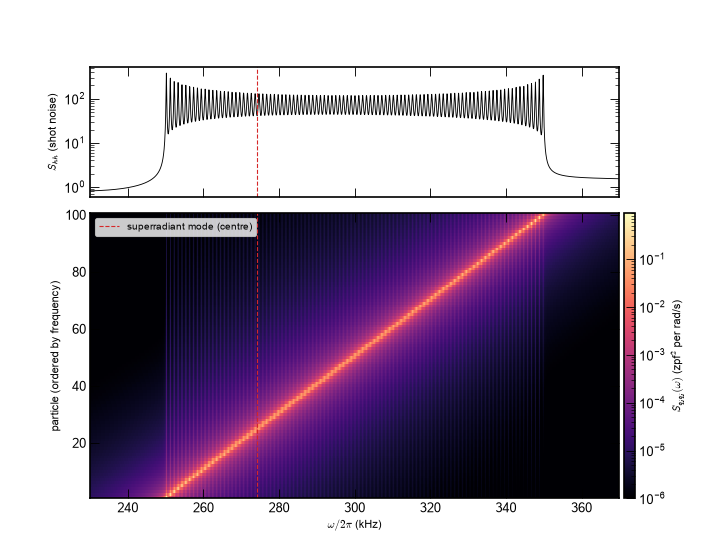

In [ ]:
modes = normal_modes(mtrap)
bright = np.argmax(modes['γ'])

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 7), sharex=True, height_ratios=(1, 2.2))
ax1.semilogy(f, S_hh, color='k', lw=0.8)
ax1.axvline(modes['Ω'][bright] / kHz, color='tab:red', ls='--', lw=1)
ax1.set_ylabel(r'$S_{hh}$ (shot noise)')
mesh = ax2.pcolormesh(f, np.arange(1, N + 1), psd_lam.T, norm=LogNorm(vmin=1e-6, vmax=psd_lam.max()), cmap='magma', shading='auto')
ax2.axvline(modes['Ω'][bright] / kHz, color='tab:red', ls='--', lw=1, label='superradiant mode (centre)')
ax2.set_xlim(f[0], f[-1])
ax2.set_xlabel(r'$\omega / 2\pi$ (kHz)')
ax2.set_ylabel('particle (ordered by frequency)')
ax2.legend(fontsize=9, loc='upper left')
colourbar = fig.colorbar(mesh, cax=ax2.inset_axes([1.01, 0, 0.02, 1]), label=r'$S_{q_jq_j}(\omega)$ (zpf$^2$ per rad/s)')
fig.subplots_adjust(right=0.86, hspace=0.08)

Top: the light leaving the cavity. Bottom: the motion of each of the 100 particles. Each particle
keeps its own narrow line on the diagonal, but off the diagonal every particle also moves across the
whole band: that broad background is the collective mode of section 3 (dashed red: its centre),
and it also lifts the plateau of the cavity output between the comb's lines. The independent routes
agree to $10^{-14}$ everywhere on the grid.

## 3. One superradiant mode, ninety-nine subradiant ones

Diagonalise the drift matrix: each mechanical normal mode has a frequency $\Omega_k$, an energy
damping rate $\gamma_k$, and a participation ratio counting how many particles take part in it.

superradiant mode: Ω/2π = 274.25 kHz, γ/2π = 133.9 kHz, participation 95.0 of 100 particles, cavity weight 0.36
the other 99 modes: γ/2π = 0.128-0.455 kHz (mean 0.369), participation 1.1-3.2
alone in the cavity, the same particles: γ/2π = 0.849-0.930 kHz (mean 0.907)

sum rule: Σγ = 390.354861 kHz·2π, κ + ΣΓ_j = 390.354861 kHz·2π
the cavity-like mode keeps γ/2π = 219.9 kHz of κ/2π = 390.4 kHz; the mechanical modes get 170.4 kHz, 79% of it in the superradiant mode


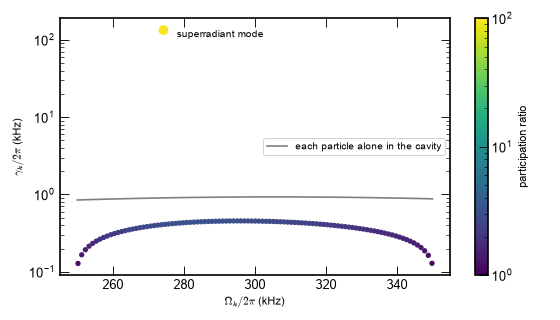

In [ ]:
others = np.arange(N) != bright
print(f'superradiant mode: Ω/2π = {modes["Ω"][bright] / kHz:.2f} kHz, γ/2π = {modes["γ"][bright] / kHz:.1f} kHz,'
      f' participation {modes["participation"][bright]:.1f} of {N} particles, cavity weight {modes["cavity_weight"][bright]:.2f}')
print(f'the other {N - 1} modes: γ/2π = {modes["γ"][others].min() / kHz:.3f}-{modes["γ"][others].max() / kHz:.3f} kHz'
      f' (mean {modes["γ"][others].mean() / kHz:.3f}), participation {modes["participation"][others].min():.1f}-{modes["participation"][others].max():.1f}')
print(f'alone in the cavity, the same particles: γ/2π = {γ_alone.min() / kHz:.3f}-{γ_alone.max() / kHz:.3f} kHz (mean {γ_alone.mean() / kHz:.3f})')

# sum rule: the trace of the drift matrix is -(κ + ΣΓ_j), so the damping rates of all modes add up to κ + ΣΓ_j
total = np.sum(-2 * modes['all_λ'].real) / 2          # each mode appears at ±Ω
print(f'\nsum rule: Σγ = {total / kHz:.6f} kHz·2π, κ + ΣΓ_j = {(mtrap.cavity.κ + sum(d.Γ for d in dims)) / kHz:.6f} kHz·2π')
mechanical_share = modes['γ'].sum()
print(f'the cavity-like mode keeps γ/2π = {modes["γ_cavity"] / kHz:.1f} kHz of κ/2π = {mtrap.cavity.κ / kHz:.1f} kHz;'
      f' the mechanical modes get {mechanical_share / kHz:.1f} kHz, {100 * modes["γ"][bright] / mechanical_share:.0f}% of it in the superradiant mode')

fig, ax = plt.subplots(figsize=(7, 4))
points = ax.scatter(modes['Ω'] / kHz, modes['γ'] / kHz, c=modes['participation'], cmap='viridis', norm=LogNorm(1, N),
                    s=np.where(np.arange(N) == bright, 60, 14), zorder=3)
ax.annotate('superradiant mode', (modes['Ω'][bright] / kHz, modes['γ'][bright] / kHz), xytext=(12, -4),
            textcoords='offset points', fontsize=9, va='center')
ax.plot(Ωs / kHz, γ_alone / kHz, color='grey', lw=1.5, label='each particle alone in the cavity')
ax.set_yscale('log')
ax.set_xlim(Ωs[0] / kHz - 5, Ωs[-1] / kHz + 5)
ax.set_xlabel(r'$\Omega_k / 2\pi$ (kHz)')
ax.set_ylabel(r'$\gamma_k / 2\pi$ (kHz)')
ax.legend(fontsize=9, loc='center right')
fig.colorbar(points, ax=ax, label='participation ratio')
fig.tight_layout()

The cavity couples to the particles only through the collective coordinate $\sum_j G_j\hat q_j$. When
the particles' frequencies are spread by more than their summed damping, that coordinate is not a
normal mode and each particle is cooled almost as if alone. Here the summed damping
$N\Gamma_1/2\pi \approx 93$ kHz is comparable to the 100 kHz span, and the collective coordinate *is* a
mode: it involves 95 of the 100 particles, mixes strongly with the cavity, and takes about four
fifths of all the damping the cavity hands out - the mechanical analogue of superradiance (and of
the "cavity protection" of inhomogeneously broadened spin ensembles). The sum rule fixes the total,
so the 99 modes left over are *subradiant*: each is damped at roughly 40% of the rate the same
particle would get alone.

## 4. What the subradiant modes cost: phonons, two ways

The steady-state occupation of every particle, from the Lyapunov equation (time domain), and -
independently - from integrating its position spectrum, $\int S_{q_jq_j}\,d\omega/2\pi = \langle\hat q_j^2\rangle = 2n_j + 1$
(frequency domain). The integral needs every line resolved at positive *and* negative frequency and
the tails out to MHz, so it uses a piecewise-uniform grid of about 10 000 points.

10020 points in 31 s; <q_j²> from ∫S vs Lyapunov over all 100 particles: relative difference -3.1e-05 to +6.4e-05
(<q²> - <p²>)/(<q²> + <p²>) from Lyapunov: -1.4e-03 to +8.9e-04
mean occupation: 82.5 phonons collectively, 23.1 one at a time (ratio 3.58); hottest particle 190 phonons


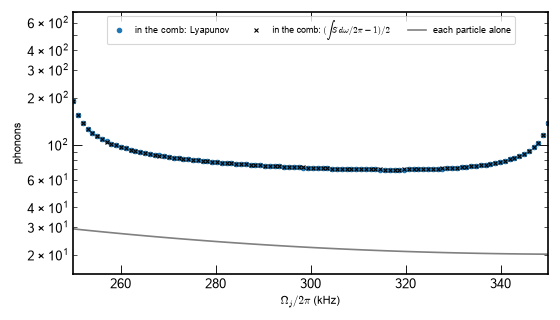

In [ ]:
V = steady_state_covariance(mtrap)
n_collective = mean_phonon_numbers(dimension_covariance(mtrap, V, mtrap.labels))
q2_lyapunov = np.array([dimension_covariance(mtrap, V, [label])[0, 0] for label in mtrap.labels])
p2_lyapunov = np.array([dimension_covariance(mtrap, V, [label])[1, 1] for label in mtrap.labels])

# piecewise-uniform segments that abut exactly (start, stop, step in kHz): the trapezoid rule is
# spectrally accurate on a uniform grid, but loses that wherever coarse and fine points interleave
segments = [(-3000, -600, 2), (-600, -360, 0.5), (-360, -240, 0.04), (-240, -100, 0.5), (-100, 100, 2),
            (100, 240, 0.5), (240, 360, 0.04), (360, 600, 0.5), (600, 3000, 2)]
grid = np.concatenate([start + step * np.arange(round((stop - start) / step)) for start, stop, step in segments]) * kHz
integration = comb(N, ω_range=grid)
(psd, _), seconds = timed(integration.all_position_power_spectra, LAM)
q2 = np.trapezoid(psd, integration.ω_range, axis=0) / (2 * np.pi)
difference = q2 / q2_lyapunov - 1
asymmetry = (q2_lyapunov - p2_lyapunov) / (q2_lyapunov + p2_lyapunov)
print(f'{len(integration.ω_range)} points in {seconds:.0f} s; <q_j²> from ∫S vs Lyapunov over all {N} particles:'
      f' relative difference {difference.min():+.1e} to {difference.max():+.1e}')
print(f'(<q²> - <p²>)/(<q²> + <p²>) from Lyapunov: {asymmetry.min():+.1e} to {asymmetry.max():+.1e}')
n_spectral = (q2 - 1) / 2      # the phonon number if <p²> were exactly <q²>
print(f'mean occupation: {n_collective.mean():.1f} phonons collectively, {n_alone.mean():.1f} one at a time'
      f' (ratio {n_collective.mean() / n_alone.mean():.2f}); hottest particle {n_collective.max():.0f} phonons')

fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogy(Ωs / kHz, n_collective, 'o', ms=4, color='tab:blue', label='in the comb: Lyapunov')
ax.semilogy(Ωs / kHz, n_spectral, 'x', ms=4, color='k', label=r'in the comb: $(\int S\,d\omega/2\pi - 1)/2$')
ax.semilogy(Ωs / kHz, n_alone, color='grey', lw=1.5, label='each particle alone')
ax.set_xlim(Ωs[0] / kHz, Ωs[-1] / kHz)
ax.set_ylim(15, 700)
ax.set_xlabel(r'$\Omega_j / 2\pi$ (kHz)')
ax.set_ylabel('phonons')
ax.legend(fontsize=8, loc='upper center', ncols=3)
fig.tight_layout()

The two routes agree on $\langle\hat q_j^2\rangle$ to about $10^{-4}$ for all 100 particles (the residue
is mostly the truncated tails, which make the integral slightly too small). The phonon number also
needs $\langle\hat p_j^2\rangle$, which differs from $\langle\hat q_j^2\rangle$ by up to about 0.1% here,
because the counter-rotating parts of the coupling make the motion slightly phase-asymmetric; on
this plot the crosses, which assume $\langle\hat p_j^2\rangle = \langle\hat q_j^2\rangle$, are
indistinguishable from the dots.
Every particle is hotter in the comb than it would be alone, and the edge particles - whose modes
overlap least with the collective one - are hottest.

## 5. When does the comb turn collective?

Grow $N$ at fixed span. Below some $N$ the particles are cooled as if alone; above it the
superradiant mode appears, delocalised over the comb, and the mean occupation climbs:

In [ ]:
sizes = [5, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 120, 150, 200]
scan = []
for n_particles in sizes:
    mt = comb(n_particles)
    m = normal_modes(mt)
    b = np.argmax(m['γ'])
    _, n1 = alone(mt)
    scan.append((n_particles, occupations(mt).mean() / n1.mean(), m['γ'][b], m['participation'][b] / n_particles))
scan = np.array(scan)
for row in scan:
    print(f'N = {row[0]:3.0f}: n̄/n̄_alone = {row[1]:6.2f}, fastest mode γ/2π = {row[2] / kHz:6.1f} kHz, participation/N = {row[3]:.2f}')

N =   5: n̄/n̄_alone =   0.99, fastest mode γ/2π =    0.9 kHz, participation/N = 0.20
N =  10: n̄/n̄_alone =   0.98, fastest mode γ/2π =    1.0 kHz, participation/N = 0.10
N =  20: n̄/n̄_alone =   1.02, fastest mode γ/2π =    1.2 kHz, participation/N = 0.05
N =  30: n̄/n̄_alone =   1.12, fastest mode γ/2π =    1.3 kHz, participation/N = 0.04
N =  40: n̄/n̄_alone =   1.29, fastest mode γ/2π =    1.5 kHz, participation/N = 0.04
N =  50: n̄/n̄_alone =   1.51, fastest mode γ/2π =    1.8 kHz, participation/N = 0.05
N =  60: n̄/n̄_alone =   1.80, fastest mode γ/2π =    7.3 kHz, participation/N = 0.20
N =  70: n̄/n̄_alone =   2.15, fastest mode γ/2π =   31.3 kHz, participation/N = 0.58
N =  80: n̄/n̄_alone =   2.56, fastest mode γ/2π =   58.3 kHz, participation/N = 0.78
N =  90: n̄/n̄_alone =   3.04, fastest mode γ/2π =   89.5 kHz, participation/N = 0.89
N = 100: n̄/n̄_alone =   3.58, fastest mode γ/2π =  133.9 kHz, participation/N = 0.95
N = 120: n̄/n̄_alone =   4.84, fastest mode γ/2π =  17

Now repeat for combs of different span, finding (by bisection in $N$) where the fastest mode first
involves half of the particles:

span    25 kHz: collective from N =  20, i.e. N·Γ_1 / span = 0.74
span    50 kHz: collective from N =  37, i.e. N·Γ_1 / span = 0.69
span   100 kHz: collective from N =  68, i.e. N·Γ_1 / span = 0.63
span   200 kHz: collective from N = 120, i.e. N·Γ_1 / span = 0.56


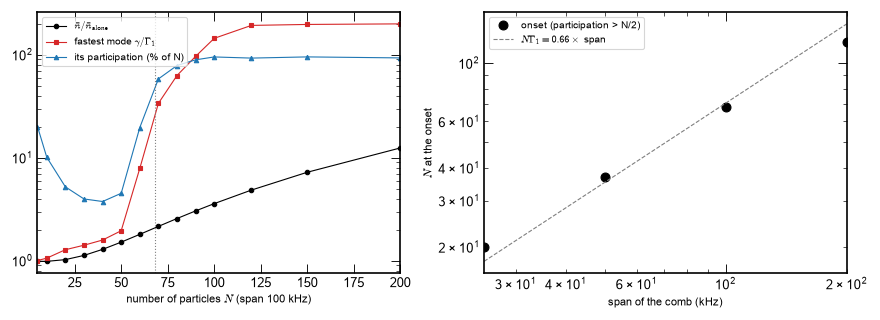

In [ ]:
def collective_fraction(n_particles, span):
    m = normal_modes(comb(int(n_particles), span=span))
    return m['participation'][np.argmax(m['γ'])] / n_particles

thresholds = {}
for span in np.array([25, 50, 100, 200]) * kHz:
    lo, hi = 2, 260
    while hi - lo > 1:                     # smallest N with participation/N above 0.5
        n_mid = (lo + hi) // 2
        lo, hi = (lo, n_mid) if collective_fraction(n_mid, span) > 0.5 else (n_mid, hi)
    thresholds[span] = hi
    print(f'span {span / kHz:5.0f} kHz: collective from N = {hi:3d}, i.e. N·Γ_1 / span = {hi * Γ1 / span:.2f}')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.semilogy(scan[:, 0], scan[:, 1], 'o-', color='k', ms=4, label=r'$\bar n / \bar n_\mathrm{alone}$')
ax1.semilogy(scan[:, 0], scan[:, 2] / Γ1, 's-', color='tab:red', ms=4, label=r'fastest mode $\gamma / \Gamma_1$')
ax1.semilogy(scan[:, 0], scan[:, 3] * 100, '^-', color='tab:blue', ms=4, label='its participation (% of N)')
ax1.axvline(thresholds[100 * kHz], color='grey', ls=':', lw=1)
ax1.set_xlim(scan[0, 0], scan[-1, 0])
ax1.set_xlabel('number of particles $N$ (span 100 kHz)')
ax1.legend(fontsize=9, loc='upper left')
spans = np.array(list(thresholds)) / kHz
ax2.loglog(spans, list(thresholds.values()), 'o', color='k', label='onset (participation > N/2)')
fit = np.mean(np.array(list(thresholds.values())) * Γ1 / (spans * kHz))
ax2.loglog(spans, fit * spans * kHz / Γ1, '--', color='grey', label=f'$N\\Gamma_1 = {fit:.2f}\\times$ span')
ax2.set_xlim(spans[0], spans[-1])
ax2.set_xlabel('span of the comb (kHz)')
ax2.set_ylabel('$N$ at the onset')
ax2.legend(fontsize=9, loc='upper left')
fig.tight_layout()

The onset grows almost in proportion to the span: across an eightfold range of spans, the comb
turns collective when $N\Gamma_1$ reaches 0.56-0.74 of the frequency spread - the criterion for
superradiance from an inhomogeneously broadened ensemble. Above the onset the superradiant mode's
damping approaches $\kappa/2$ (195 kHz), where it is a polariton sharing the cavity's linewidth, and
every particle added after that makes the others hotter.

## 6. The collective optical spring, and where it breaks

The red-detuned cavity also softens the collective mode. For $N$ particles at one frequency
$\Omega$ the static optical spring of the bright mode is $N$ times one particle's, and the bright
mode's frequency reaches zero - the array becomes statically unstable - at

$$
g_c^2 = \frac{\Omega\,(\Delta^2 + \kappa^2/4)}{4N|\Delta|}, \qquad\text{i.e.}\qquad N_c = \frac{\Omega\,(\Delta^2 + \kappa^2/4)}{4|\Delta|\,g^2} .
$$

Find the threshold coupling numerically (where the largest real part of a drift-matrix eigenvalue
crosses zero) and compare:

In [ ]:
def growth(g, n_particles, degenerate):
    return np.max(np.linalg.eigvals(comb(n_particles, g=-g, degenerate=degenerate).drift_matrix).real)

Ω, Δ, κ = 300 * kHz, abs(CAVITY['Δ']), mtrap.cavity.κ
print('  N   g_c/2π numerical (kHz)   formula (kHz)   relative difference   spread comb, g_c/2π (kHz)')
# the root finder builds systems on both sides of the threshold, and levisim logs a WARNING for each
# unstable one: lower the console to ERROR while it runs
set_console_level('ERROR')
try:
    for n_particles in (1, 10, 100):
        numerical = brentq(lambda g: growth(g, n_particles, True) + 1e-3, 1 * kHz, 500 * kHz, xtol=1e-9 * kHz)
        formula = np.sqrt(Ω * (Δ**2 + κ**2 / 4) / (4 * n_particles * Δ))
        spread = brentq(lambda g: growth(g, n_particles, False) + 1e-3, 1 * kHz, 500 * kHz, xtol=1e-6 * kHz) if n_particles > 1 else numerical
        print(f'{n_particles:4d}   {numerical / kHz:22.8f}   {formula / kHz:13.8f}   {numerical / formula - 1:+19.1e}   {spread / kHz:25.3f}')
finally:
    set_console_level('WARNING')   # levisim's default
print(f'\nN_c at g/2π = -10 kHz: {Ω * (Δ**2 + κ**2 / 4) / (4 * Δ * (10 * kHz)**2):.0f} particles (degenerate comb)')
default = MultiTrap(num_traps=1, Cartesian_axes_per_trap=1, gas_kwargs=DEFAULT_gas_kwargs,
                    cavity_kwargs=DEFAULT_cavity_kwargs, ω_range=np.array([0.0])).dimensions['x1']
Δ_d, κ_d = abs(DEFAULT_cavity_kwargs['Δ']), default.multitrap.cavity.κ
print(f'levisim physical defaults (Ω/2π = {default.Ω / kHz:.1f} kHz, g/2π = {default.g / kHz:.1f} kHz, Δ/2π = -{Δ_d / kHz:.0f} kHz):'
      f' N_c = {default.Ω * (Δ_d**2 + κ_d**2 / 4) / (4 * Δ_d * default.g**2):.0f} identical particles')

  N   g_c/2π numerical (kHz)   formula (kHz)   relative difference   spread comb, g_c/2π (kHz)
   1             178.95125746    178.95125751              -2.4e-10                     178.951
  10              56.58935637     56.58935639              -2.4e-10                      56.265
 100              17.89512575     17.89512575              -2.4e-10                      17.810

N_c at g/2π = -10 kHz: 320 particles (degenerate comb)
levisim physical defaults (Ω/2π = 156.3 kHz, g/2π = -22.2 kHz, Δ/2π = -450 kHz): N_c = 42 identical particles


For a degenerate comb the eigenvalue threshold matches the formula to better than $10^{-9}$; at
threshold the bright mode's frequency is zero, so the static formula is exact there. Spreading the
frequencies over 100 kHz lowers the threshold coupling by only about 0.5%. At the coupling used here,
$g/2\pi = -10$ kHz, about 320 identical particles would destabilise the array; with levisim's physical
default tweezer, bead and cavity (stronger coupling, lower frequency) the limit is a few tens.

## 7. What it costs

Time per frequency point against $N$, for the homodyne spectrum (LAM and the closed form) and for
all position spectra (LAM, TNT, closed form), fastest of three repeats:

homodyne, LAM                 0.05      0.14      0.73      2.32      9.40  ms at N = 10, 25, 50, 100, 200
homodyne, closed form         0.16      0.27      0.50      1.34      2.35  ms at N = 10, 25, 50, 100, 200
positions, LAM                0.08      0.24      1.00      3.33     12.09  ms at N = 10, 25, 50, 100, 200
positions, TNT                0.03      0.35      1.31      4.95     27.12  ms at N = 10, 25, 50, 100, 200
positions, closed form        0.87      3.78     14.02       nan       nan  ms at N = 10, 25, 50, 100, 200


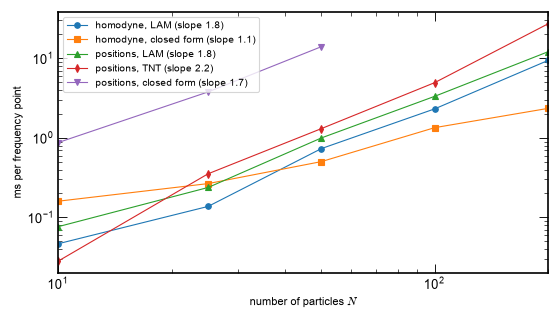

In [ ]:
def per_point(mt, function, method, repeats=3):
    best = np.inf
    for _ in range(repeats):
        for cached in ('quantum_operator_spectral_density_array', 'position_power_spectra_array'):
            mt.__dict__.pop(cached, None)                                   # TNT caches its results
        _, seconds = timed(getattr(mt, function), method)
        best = min(best, seconds)
    return best / len(mt.ω_range)

cost_sizes = [10, 25, 50, 100, 200]
routes = {
    'homodyne, LAM': ('homodyne_spectrum', LAM, 200),
    'homodyne, closed form': ('homodyne_spectrum', CLOSED_FORM, 200),
    'positions, LAM': ('all_position_power_spectra', LAM, 200),
    'positions, TNT': ('all_position_power_spectra', TNT, 200),
    'positions, closed form': ('all_position_power_spectra', CLOSED_FORM, 50),
}
costs = {name: [] for name in routes}
for n_particles in cost_sizes:
    mt = comb(n_particles, ω_range=np.linspace(250, 350, 8) * kHz)
    for name, (function, method, largest) in routes.items():
        costs[name].append(per_point(mt, function, method) if n_particles <= largest else np.nan)

fig, ax = plt.subplots(figsize=(7, 4))
for (name, values), marker in zip(costs.items(), 'os^dv'):
    values = np.array(values)
    ok = np.isfinite(values)
    slope = np.polyfit(np.log(np.array(cost_sizes)[ok][-3:]), np.log(values[ok][-3:]), 1)[0]
    ax.loglog(np.array(cost_sizes)[ok], 1e3 * values[ok], marker + '-', ms=5, label=f'{name} (slope {slope:.1f})')
ax.set_xlim(cost_sizes[0], cost_sizes[-1])
ax.set_xlabel('number of particles $N$')
ax.set_ylabel('ms per frequency point')
ax.legend(fontsize=9, loc='upper left')
fig.tight_layout()
for name, values in costs.items():
    print(f'{name:24s}' + ''.join(f'{1e3 * v:10.2f}' for v in values) + '  ms at N = ' + ', '.join(map(str, cost_sizes)))

Slopes are fitted to the three largest sizes measured; the timings scatter from run to run,
especially on a busy machine, and only the ordering at large $N$ is robust. The
closed form gives the cavity output
without any $N\times N$ inverse and is the cheapest route to the homodyne spectrum at large $N$. Its
position spectra, as currently implemented, build each particle's block from products over all
the other particles, which is why they are measured here only up to $N = 50$; the rank-2 structure
of [`05_derangements_and_hybridisation`](../demos/05_derangements_and_hybridisation.ipynb) would allow
the same quantities at linear cost per particle. For everything else, LAM and TNT handle a
hundred particles in milliseconds per frequency point.

## Summary

- At $N = 100$ the independent routes agree: homodyne spectra from LAM and the closed form,
  position spectra from LAM, TNT and the closed form, and occupations from the Lyapunov equation and
  from the integrated spectra.
- The comb turns collective when the summed single-particle damping $N\Gamma_1$ reaches about
  0.6-0.7 of the frequency spread. Then one superradiant mode takes most of the cavity's damping
  (sum rule: the total is fixed at $\kappa + \sum\Gamma_j$), and the subradiant rest are cooled less
  than the particles would be alone. Adding particles beyond that point makes all of them hotter.
- The collective optical spring destabilises a degenerate array at $N_c = \Omega(\Delta^2 + \kappa^2/4)/(4|\Delta|g^2)$,
  confirmed to better than $10^{-9}$.

Within this model, the number of particles one cavity mode can usefully cool is set by how far
apart their frequencies are relative to their cooling rates, not by the cavity linewidth alone.